# Análisis exploratorio de datos (EDA)

## Carga y Exploración Inicial de Datos

In [1]:
# Bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib .pyplot as plt
import seaborn as sns
from sklearn . model_selection import train_test_split
from sklearn . preprocessing import StandardScaler , LabelEncoder
from sklearn . linear_model import LogisticRegression
from sklearn .svm import SVC
from sklearn . metrics import ( accuracy_score , classification_report ,confusion_matrix , roc_curve , auc)

In [2]:
#leer df y mostrar las primeras filas
df = pd.read_csv('data.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
#forma del df
print(df.shape)

print('--'*50)

#estadisticos clave
print(df.describe())

print('--'*50)






(569, 33)
----------------------------------------------------------------------------------------------------
                 id  radius_mean  texture_mean  perimeter_mean    area_mean  \
count  5.690000e+02   569.000000    569.000000      569.000000   569.000000   
mean   3.037183e+07    14.127292     19.289649       91.969033   654.889104   
std    1.250206e+08     3.524049      4.301036       24.298981   351.914129   
min    8.670000e+03     6.981000      9.710000       43.790000   143.500000   
25%    8.692180e+05    11.700000     16.170000       75.170000   420.300000   
50%    9.060240e+05    13.370000     18.840000       86.240000   551.100000   
75%    8.813129e+06    15.780000     21.800000      104.100000   782.700000   
max    9.113205e+08    28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0

## Análisis de Valores Faltantes

In [4]:
#ver nulos y tipos de datos

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
#ver todas las columnas para verificar el nombre
print(df.columns)

print('--'*50)

#eliminar columna 'unnamed' si existe
df_nuevo = df.drop(columns=['Unnamed: 32'], errors='ignore')

print('--'*50)

#forma nueva
print(df_nuevo.shape)

#datos estadisticos otra vez

print('--'*50)

print(df_nuevo.describe())


Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
(569, 32)
----------------------------------------------------------------------------------------------------
                 id  r

## Análisis de la Variable Objetivo

['M' 'B']
----------------------------------------------------------------------------------------------------
diagnosis
B    357
M    212
Name: count, dtype: int64


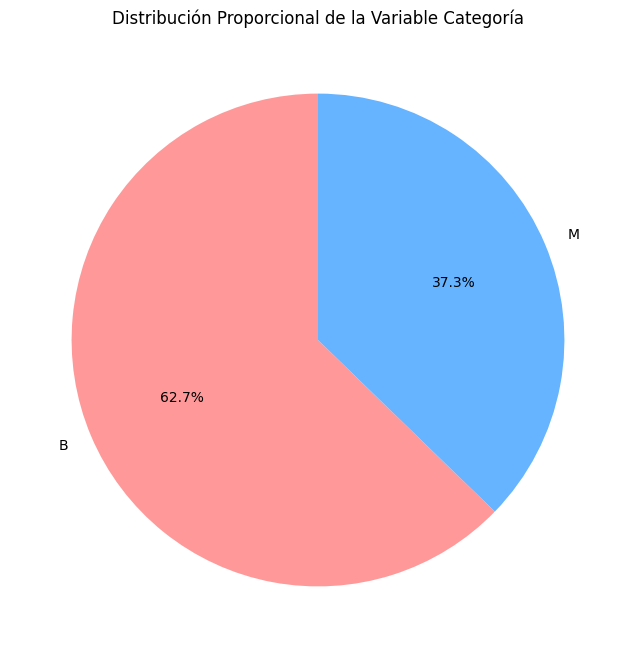

In [6]:
#ver clases
print(df_nuevo['diagnosis'].unique())

print('--'*50)

print(df_nuevo['diagnosis'].value_counts())

#grafico de tortas
# Paso 1: Obtener la frecuencia absoluta o relativa (La distribución)
datos_torta = df_nuevo['diagnosis'].value_counts()

# Extraer etiquetas y valores
etiquetas = datos_torta.index
valores = datos_torta.values

plt.figure(figsize=(8, 8)) # Definir un canvas cuadrado para que no se deforme el círculo

plt.pie(x=valores,           # Los datos numéricos (magnitud del sector)
        labels=etiquetas,    # Las etiquetas de cada sector
        autopct='%1.1f%%',   # Formato para mostrar porcentajes (1 decimal)
        startangle=90,       # Rotar el inicio para que el primer sector quede arriba
        colors=['#ff9999','#66b3ff','#99ff99']) # Colores opcionales

plt.title('Distribución Proporcional de la Variable Categoría')
plt.show()


diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64


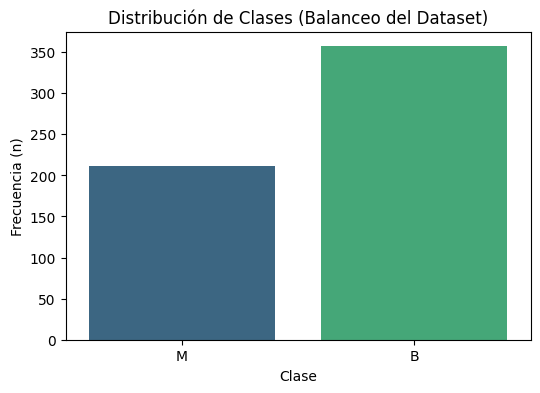

In [7]:
#Distribucion de clases
distribucion_clases = df['diagnosis'].value_counts(normalize=True)

print(distribucion_clases)

plt.figure(figsize=(6, 4))
sns.countplot(x=df_nuevo['diagnosis'],hue=df_nuevo['diagnosis'], legend=False, palette='viridis')

plt.title('Distribución de Clases (Balanceo del Dataset)')
plt.xlabel('Clase')
plt.ylabel('Frecuencia (n)')
plt.show()


Claramente, hay un desbalance de clases. las consecuencias a esto:

Sesgo del modelo: Si entrenamos un modelo directamente con estos datos desbalanceados, es probable que el modelo tenga un sesgo hacia la clase mayoritaria ('B' - Benigno). Esto significa que será muy bueno prediciendo la clase mayoritaria, pero podría tener dificultades para identificar correctamente la clase minoritaria ('M' - Maligno), que a menudo es la más crítica en diagnósticos médicos.

Métricas de evaluación engañosas: Métricas como la exactitud (accuracy) pueden ser engañosas. Un modelo podría alcanzar una alta exactitud simplemente prediciendo siempre la clase mayoritaria, sin haber aprendido realmente a identificar la minoritaria. Por ejemplo, si el 90% de los datos son 'B', un modelo que siempre predice 'B' tendrá un 90% de exactitud, lo cual parece bueno pero es inútil en la práctica.

Necesidad de técnicas de manejo de desbalance: Para construir un modelo robusto, será crucial aplicar técnicas para abordar este desbalance. Algunas estrategias comunes incluyen:

Remuestreo (Resampling): Esto puede ser oversampling (duplicar o generar nuevas muestras de la clase minoritaria) o undersampling (reducir el número de muestras de la clase mayoritaria).
Uso de algoritmos específicos: Algunos algoritmos de clasificación son más robustos al desbalance de clases que otros, o permiten ajustar ponderaciones para las clases.
Métricas de evaluación adecuadas: En lugar de solo la exactitud, deberíamos enfocarnos en métricas como la precisión, recall, f1-score, la curva ROC-AUC, o la matriz de confusión, que proporcionan una visión más completa del rendimiento del modelo en cada clase.
En resumen, el desbalance de clases es un factor importante a considerar y corregir en las etapas de preprocesamiento y modelado para asegurar que el modelo sea efectivo en la detección de ambos tipos de diagnóstico.

## Análisis Univariado

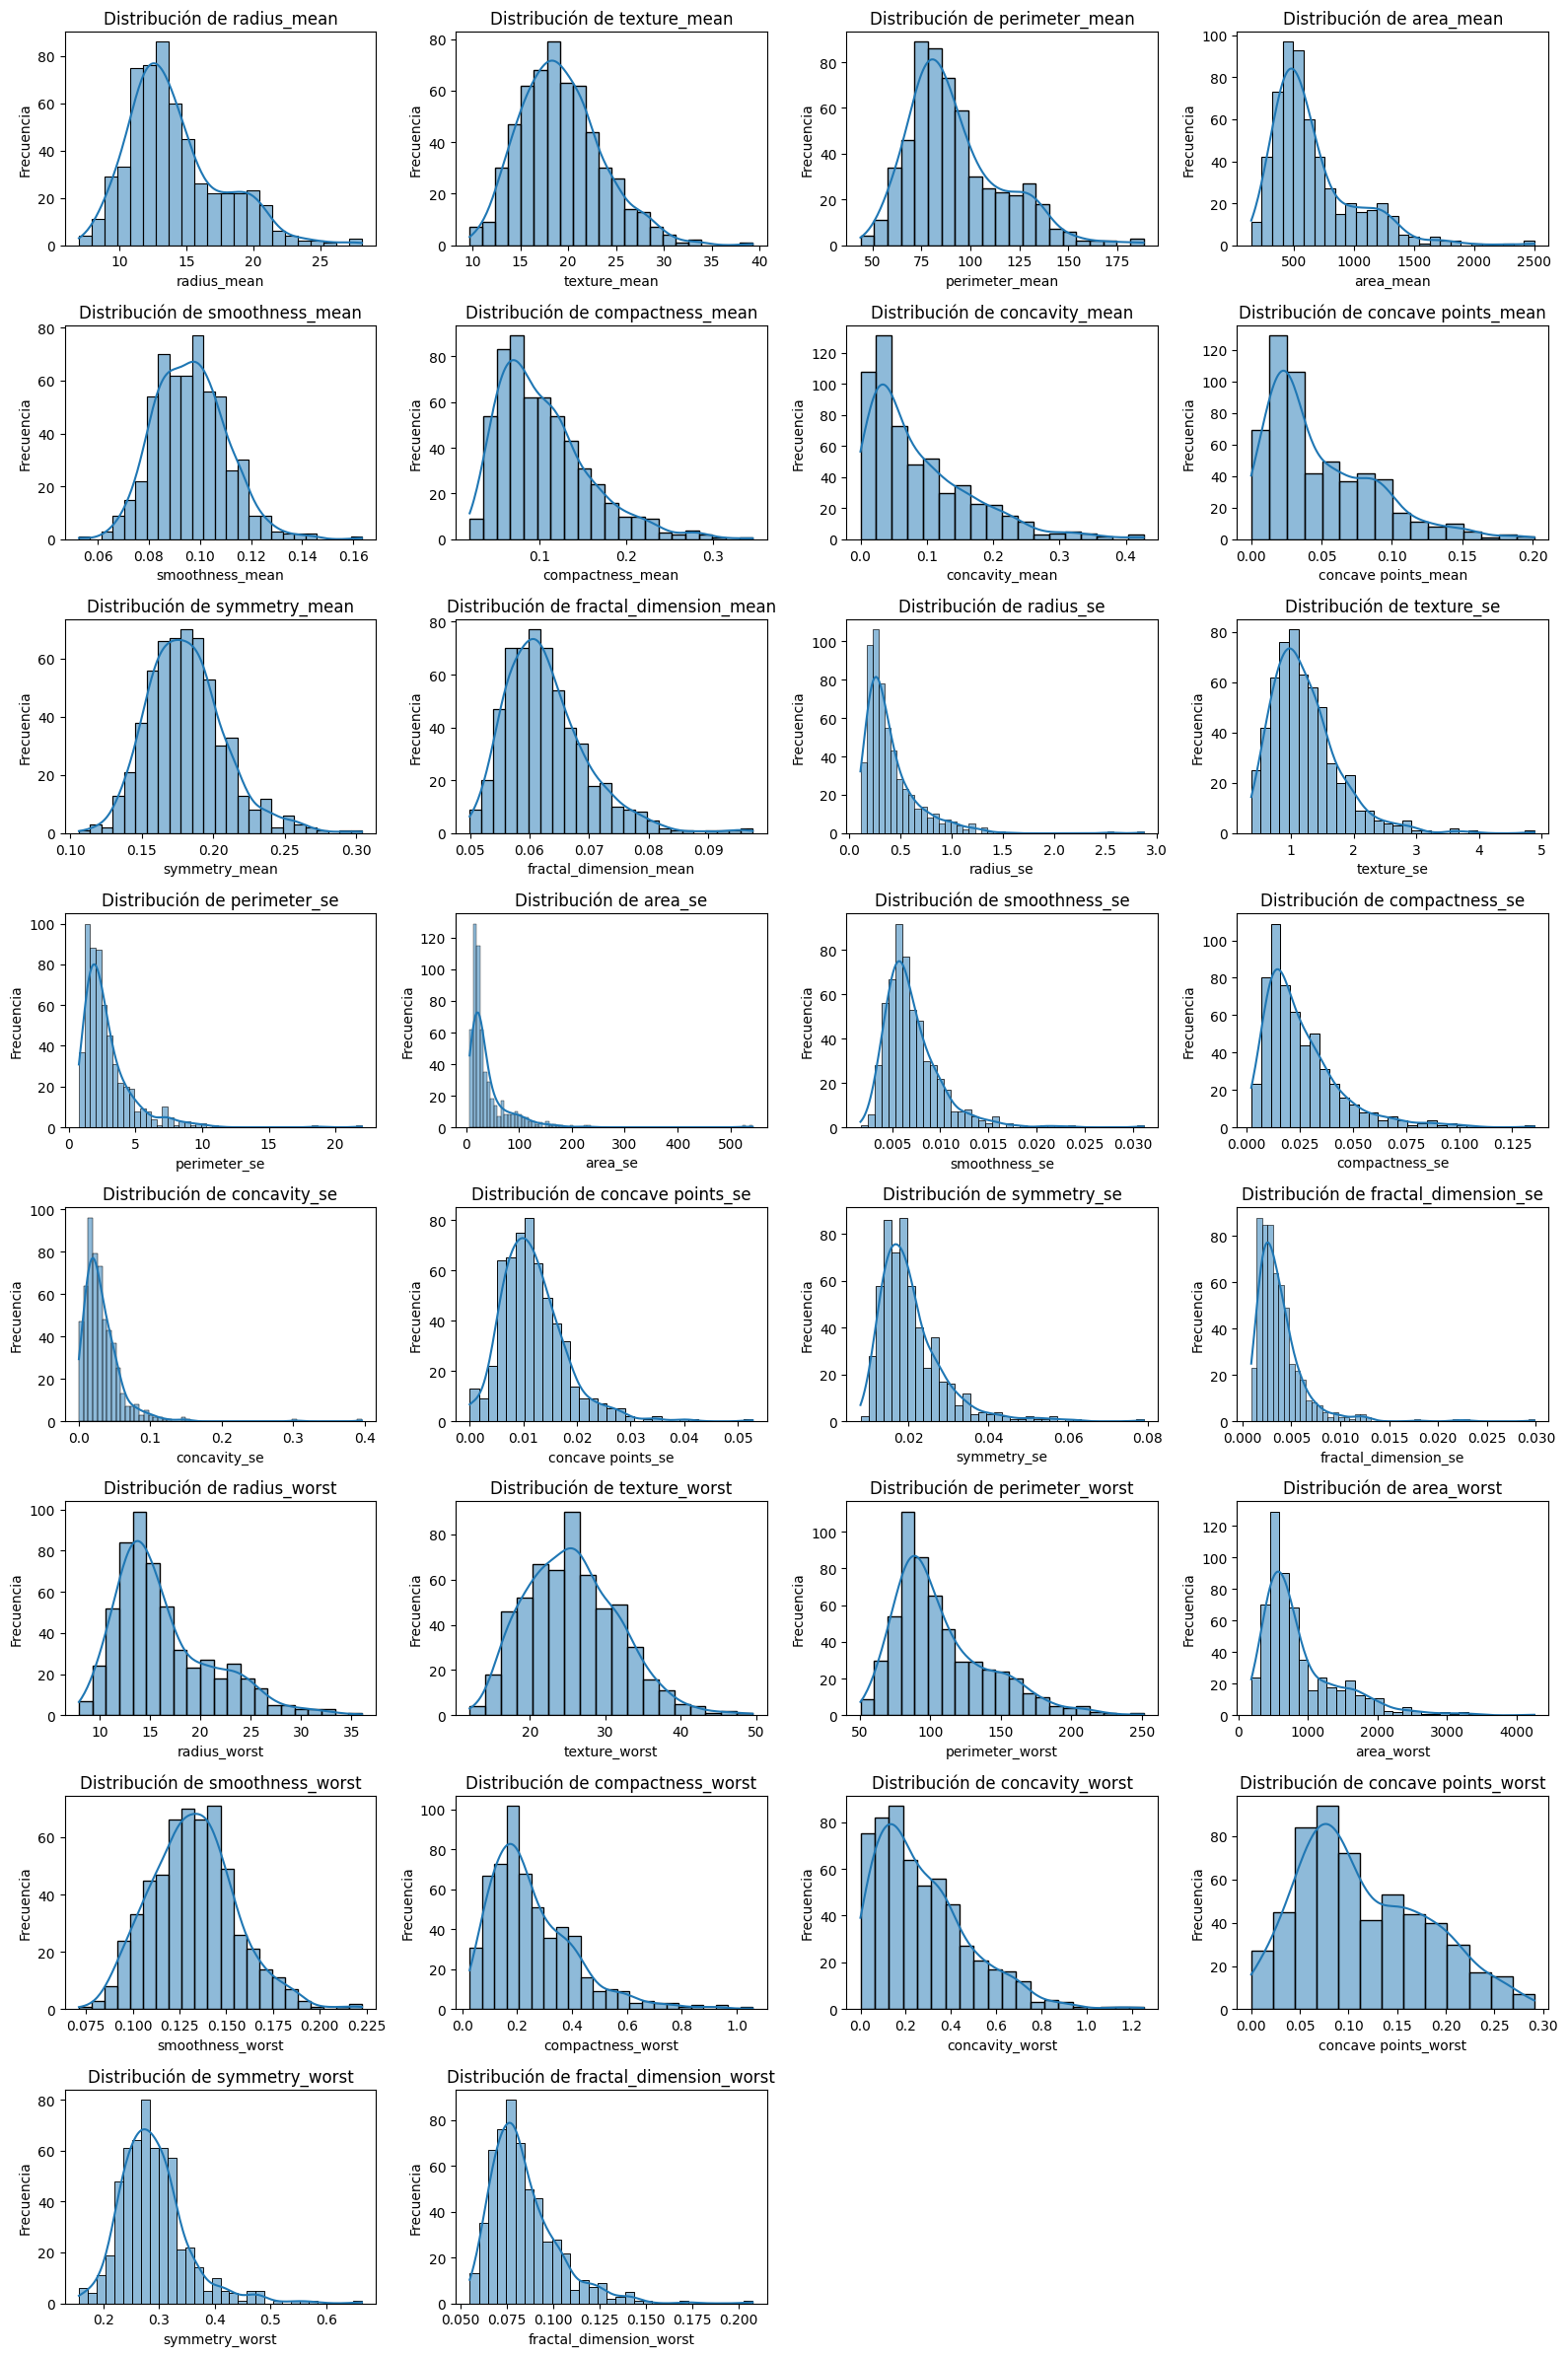

In [8]:
# histogramas para cada caracteristica numerica

# Seleccionar solo las columnas numéricas
# Excluimos 'id' y 'diagnosis' que no son numéricas para un histograma de distribución de valores.
# 'id' es un identificador, y 'diagnosis' es categórica.
numerical_cols = df_nuevo.select_dtypes(include=np.number).columns.tolist()

# Eliminar la columna 'id' si está presente, ya que es un identificador y no una característica numérica para histogramas
if 'id' in numerical_cols:
    numerical_cols.remove('id')

# Definir el número de columnas para la visualización de los histogramas
num_cols = 4
num_rows = int(np.ceil(len(numerical_cols) / num_cols))

plt.figure(figsize=(num_cols * 4, num_rows * 3))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.histplot(df_nuevo[col], kde=True) # kde=True añade una estimación de densidad de kernel
    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.tight_layout()
plt.show()

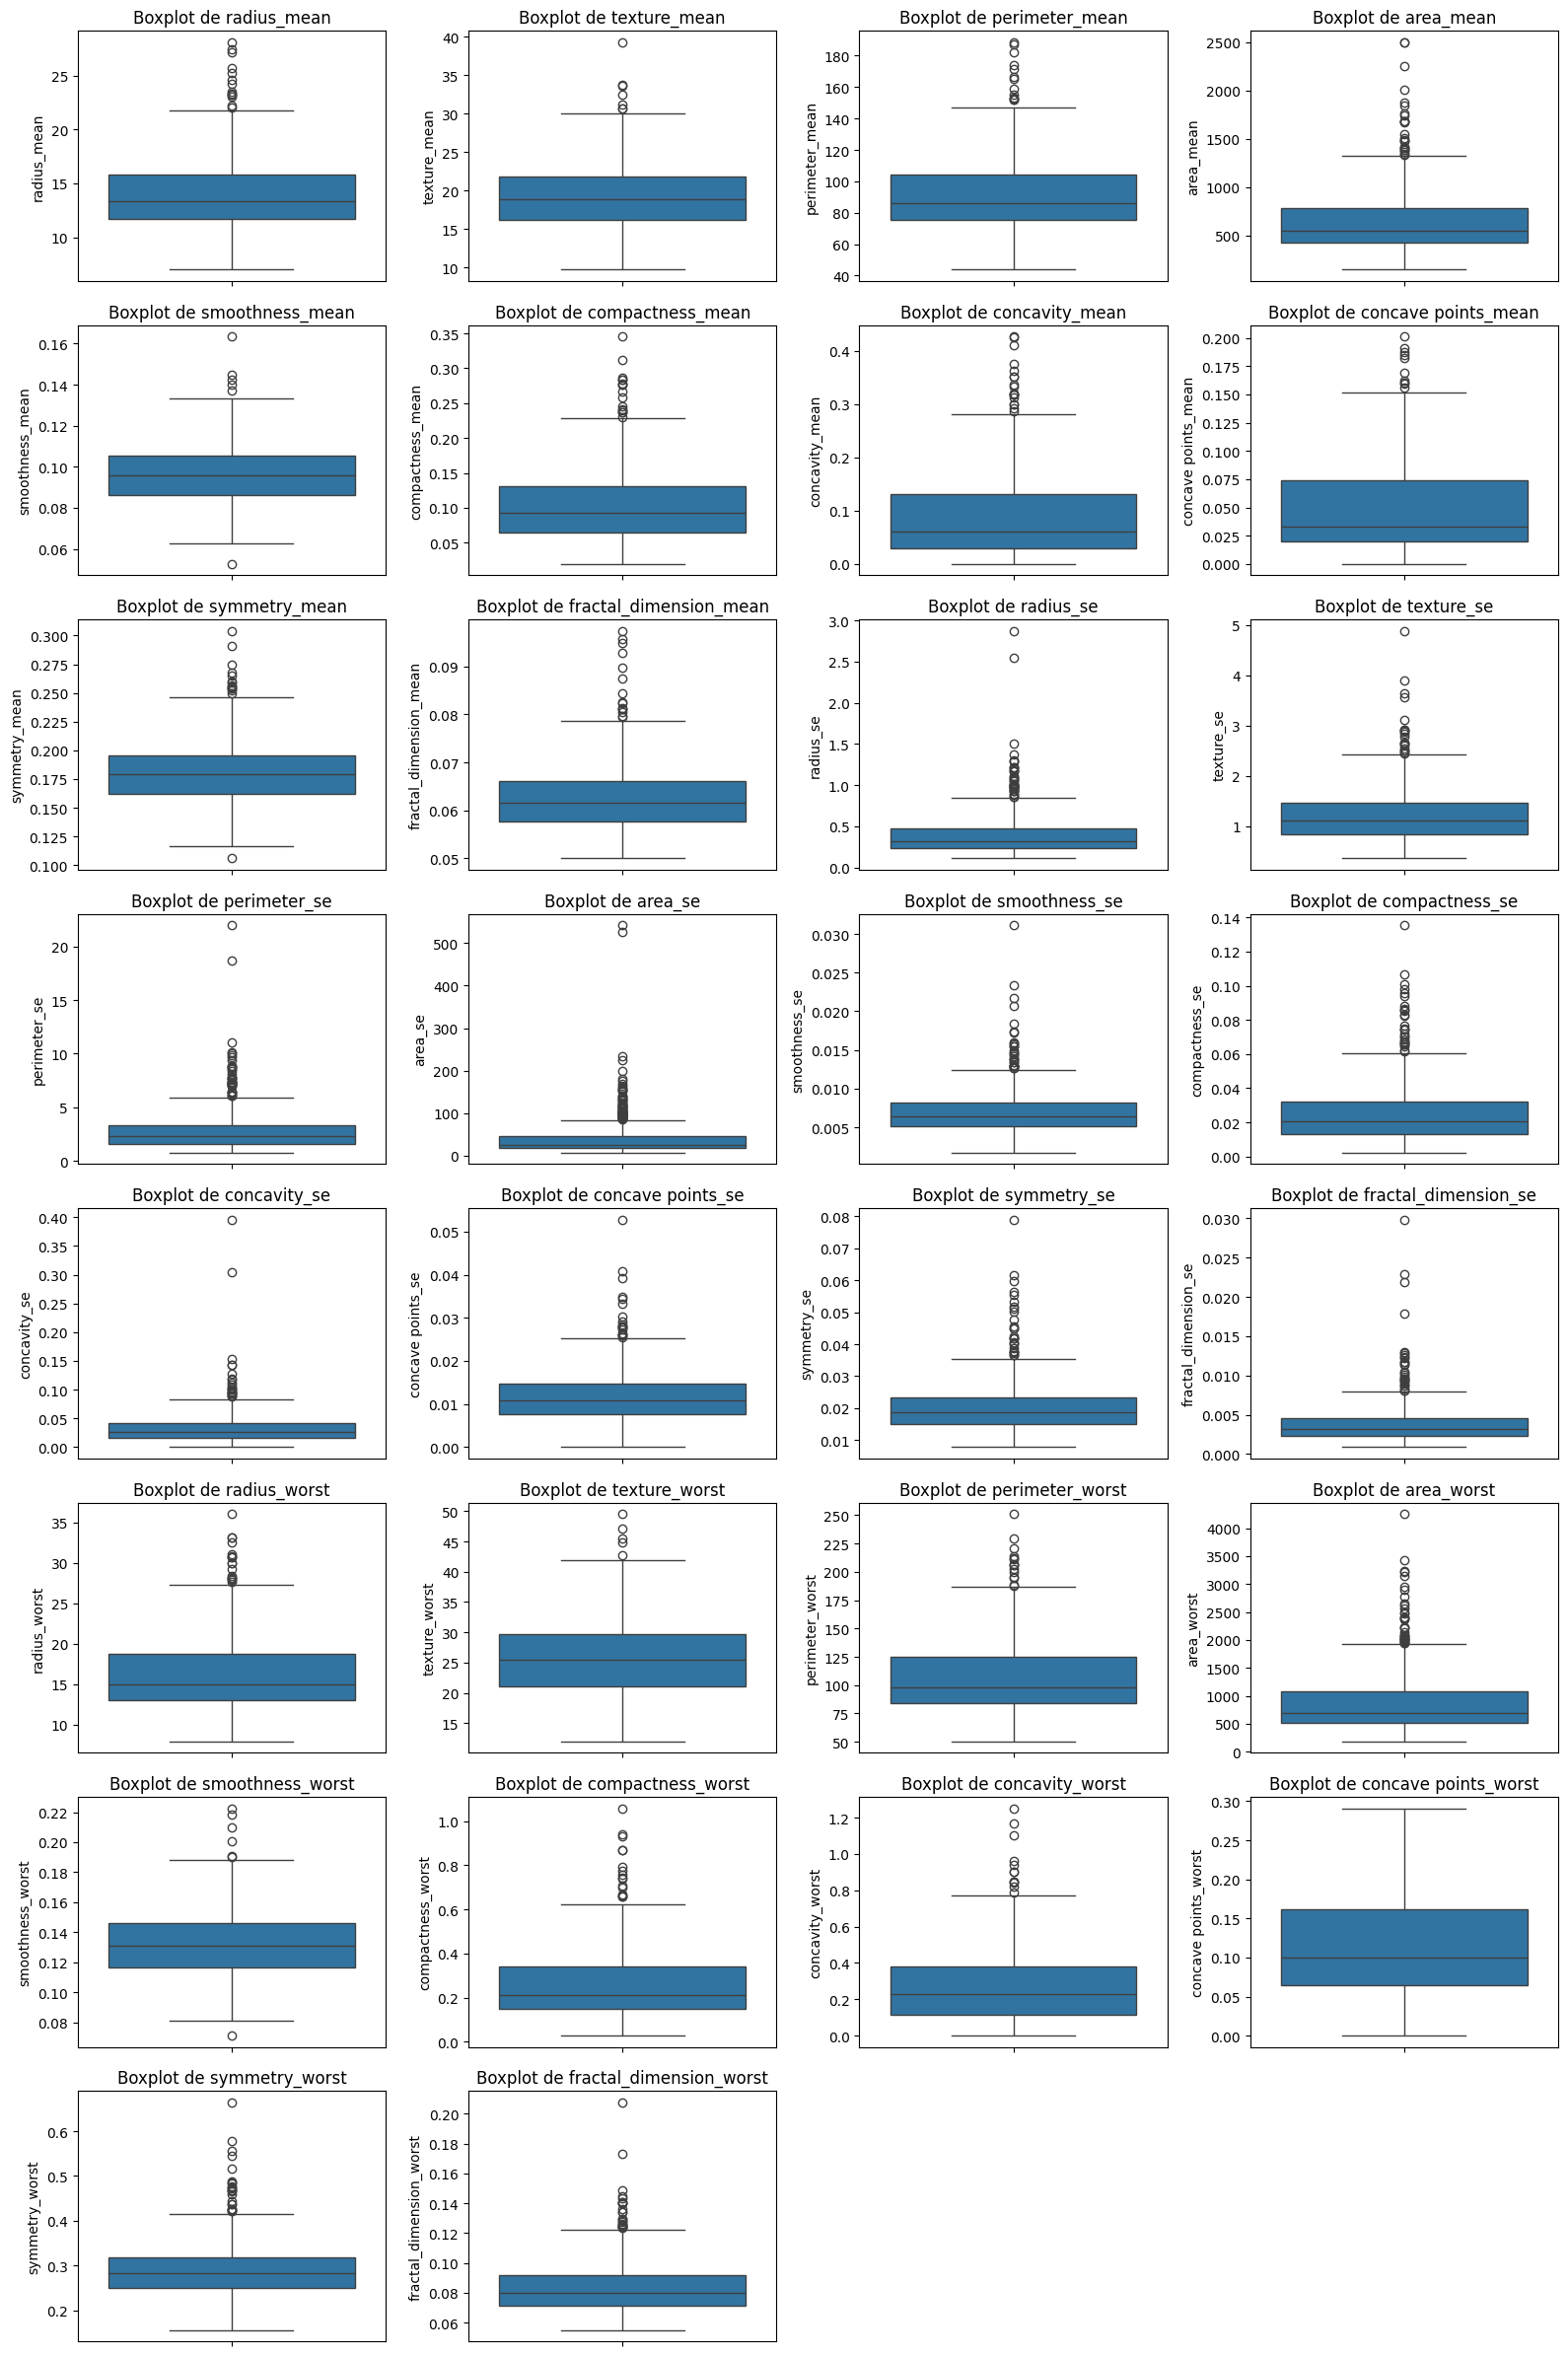

In [9]:
# boxplots para ver outliers

# Seleccionar solo las columnas numéricas, excluyendo 'id' y 'diagnosis'
numerical_cols = df_nuevo.select_dtypes(include=np.number).columns.tolist()
if 'id' in numerical_cols:
    numerical_cols.remove('id')

# Definir el número de columnas para la visualización de los boxplots
num_cols = 4
num_rows = int(np.ceil(len(numerical_cols) / num_cols))

plt.figure(figsize=(num_cols * 4, num_rows * 3))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.boxplot(y=df_nuevo[col]) # Usamos 'y' para boxplots verticales
    plt.title(f'Boxplot de {col}')
    plt.ylabel(col)
    plt.tight_layout()
plt.show()

In [10]:
# Calcular medidas de tendencia central y dispersión

# Seleccionar solo las columnas numéricas, excluyendo 'id' y 'diagnosis'
numerical_cols = df_nuevo.select_dtypes(include=np.number).columns.tolist()
if 'id' in numerical_cols:
    numerical_cols.remove('id')

# Crear un DataFrame para almacenar las medidas
summary_stats = pd.DataFrame(index=numerical_cols, columns=['Media', 'Mediana', 'Moda', 'Desviación Estándar'])

for col in numerical_cols:
    summary_stats.loc[col, 'Media'] = df_nuevo[col].mean()
    summary_stats.loc[col, 'Mediana'] = df_nuevo[col].median()
    # La moda puede tener múltiples valores, por lo que tomamos el primero si hay varios
    mode_val = df_nuevo[col].mode()
    summary_stats.loc[col, 'Moda'] = mode_val[0] if not mode_val.empty else np.nan
    summary_stats.loc[col, 'Desviación Estándar'] = df_nuevo[col].std()

print("Medidas de Tendencia Central y Dispersión:")
display(summary_stats)

Medidas de Tendencia Central y Dispersión:


,Media,Mediana,Moda,Desviación Estándar
radius_mean,14.127292,13.37,12.34,3.524049
texture_mean,19.289649,18.84,14.93,4.301036
perimeter_mean,91.969033,86.24,82.61,24.298981
area_mean,654.889104,551.1,512.2,351.914129
smoothness_mean,0.09636,0.09587,0.1007,0.014064
compactness_mean,0.104341,0.09263,0.1147,0.052813
concavity_mean,0.088799,0.06154,0.0,0.07972
concave points_mean,0.048919,0.0335,0.0,0.038803
symmetry_mean,0.181162,0.1792,0.1601,0.027414
fractal_dimension_mean,0.062798,0.06154,0.05667,0.00706


Características con moda 0.0:

Columna: concavity_mean
concavity_mean
0.00000    13
0.12040     3
0.02995     2
0.06726     2
0.01342     2
Name: count, dtype: int64

Columna: concave points_mean
concave points_mean
0.00000    13
0.02864     3
0.05778     2
0.12420     2
0.14710     2
Name: count, dtype: int64

Columna: concavity_se
concavity_se
0.00000    13
0.02681     2
0.03576     2
0.01514     2
0.02664     2
Name: count, dtype: int64

Columna: concave points_se
concave points_se
0.00000    13
0.01499     3
0.01110     3
0.01167     3
0.01384     2
Name: count, dtype: int64

Columna: concavity_worst
concavity_worst
0.0000    13
0.4504     3
0.1377     3
0.1791     2
0.2866     2
Name: count, dtype: int64

Columna: concave points_worst
concave points_worst
0.00000    13
0.17080     3
0.04306     3
0.18270     3
0.06296     3
Name: count, dtype: int64


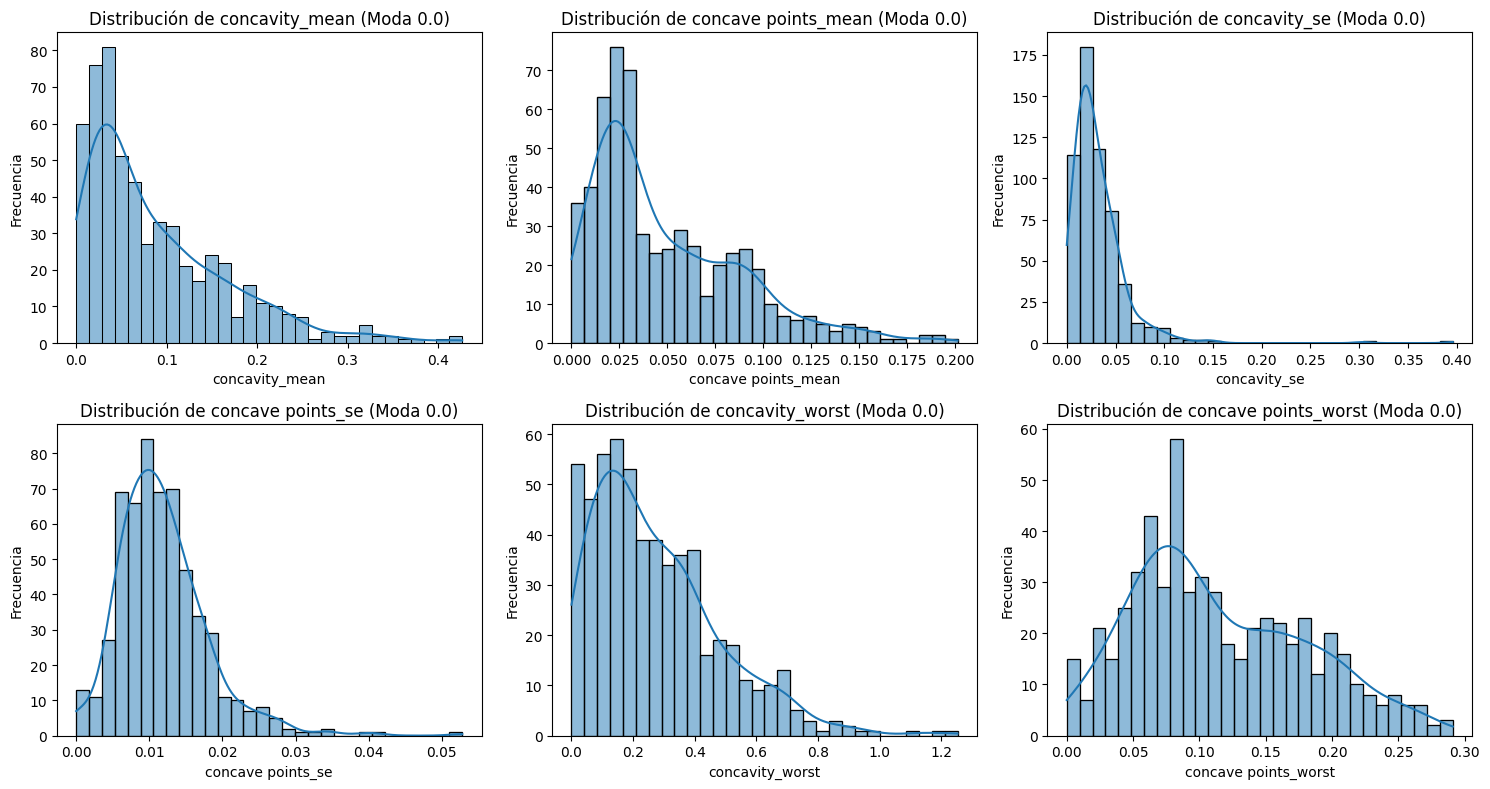

In [11]:
# Identificar características con moda 0.0
features_with_mode_zero = summary_stats[summary_stats['Moda'] == 0.0].index.tolist()

print("Características con moda 0.0:")
for col in features_with_mode_zero:
    print(f"\nColumna: {col}")
    print(df_nuevo[col].value_counts().head())

# Visualizar la distribución de estas características
num_cols = 3
num_rows = int(np.ceil(len(features_with_mode_zero) / num_cols))

plt.figure(figsize=(num_cols * 5, num_rows * 4))
for i, col in enumerate(features_with_mode_zero):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.histplot(df_nuevo[col], kde=True, bins=30)
    plt.title(f'Distribución de {col} (Moda 0.0)')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.tight_layout()
plt.show()

## Análisis Bivariado

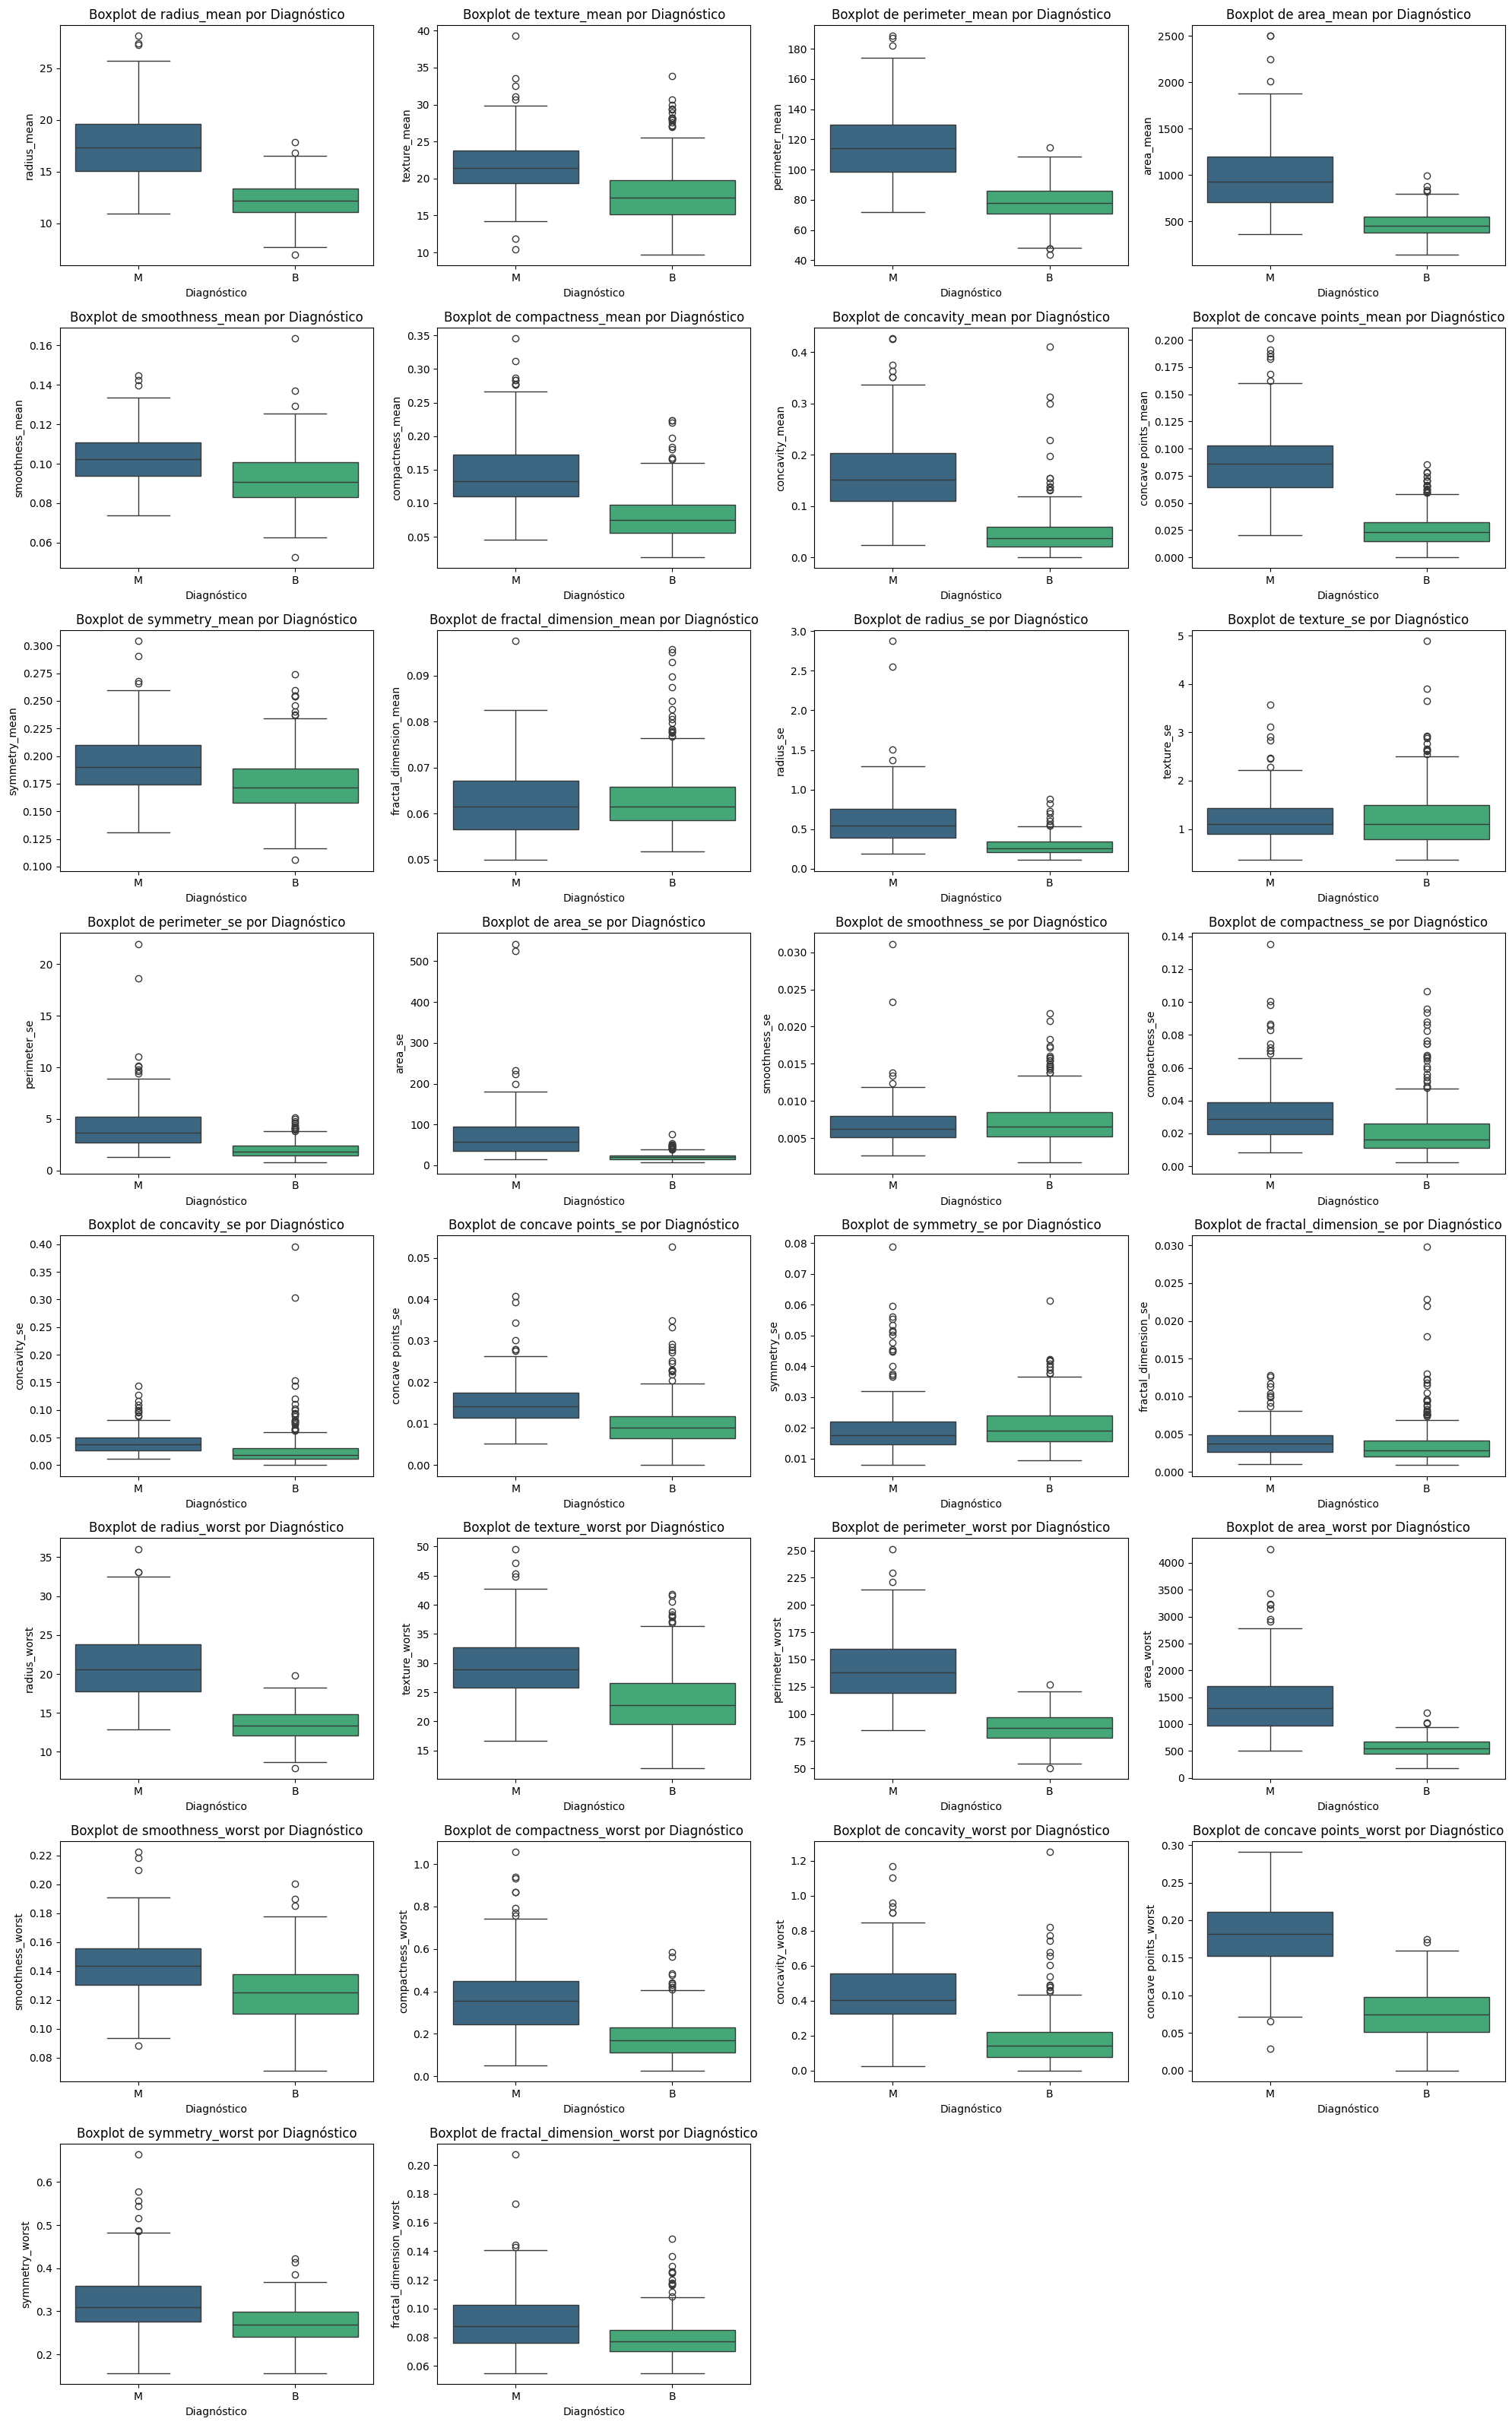

In [12]:
#boxplots comparativos de caracterısticas agrupadas por diagnostico

# Seleccionar solo las columnas numéricas, excluyendo 'id' y 'diagnosis'
numerical_cols = df_nuevo.select_dtypes(include=np.number).columns.tolist()
if 'id' in numerical_cols:
    numerical_cols.remove('id')

# Definir el número de columnas para la visualización
num_cols = 4
num_rows = int(np.ceil(len(numerical_cols) / num_cols))

plt.figure(figsize=(num_cols * 5, num_rows * 4))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.boxplot(x='diagnosis', y=col, data=df_nuevo, palette='viridis', hue='diagnosis', legend=False)
    plt.title(f'Boxplot de {col} por Diagnóstico')
    plt.xlabel('Diagnóstico')
    plt.ylabel(col)
    plt.tight_layout()
plt.show()

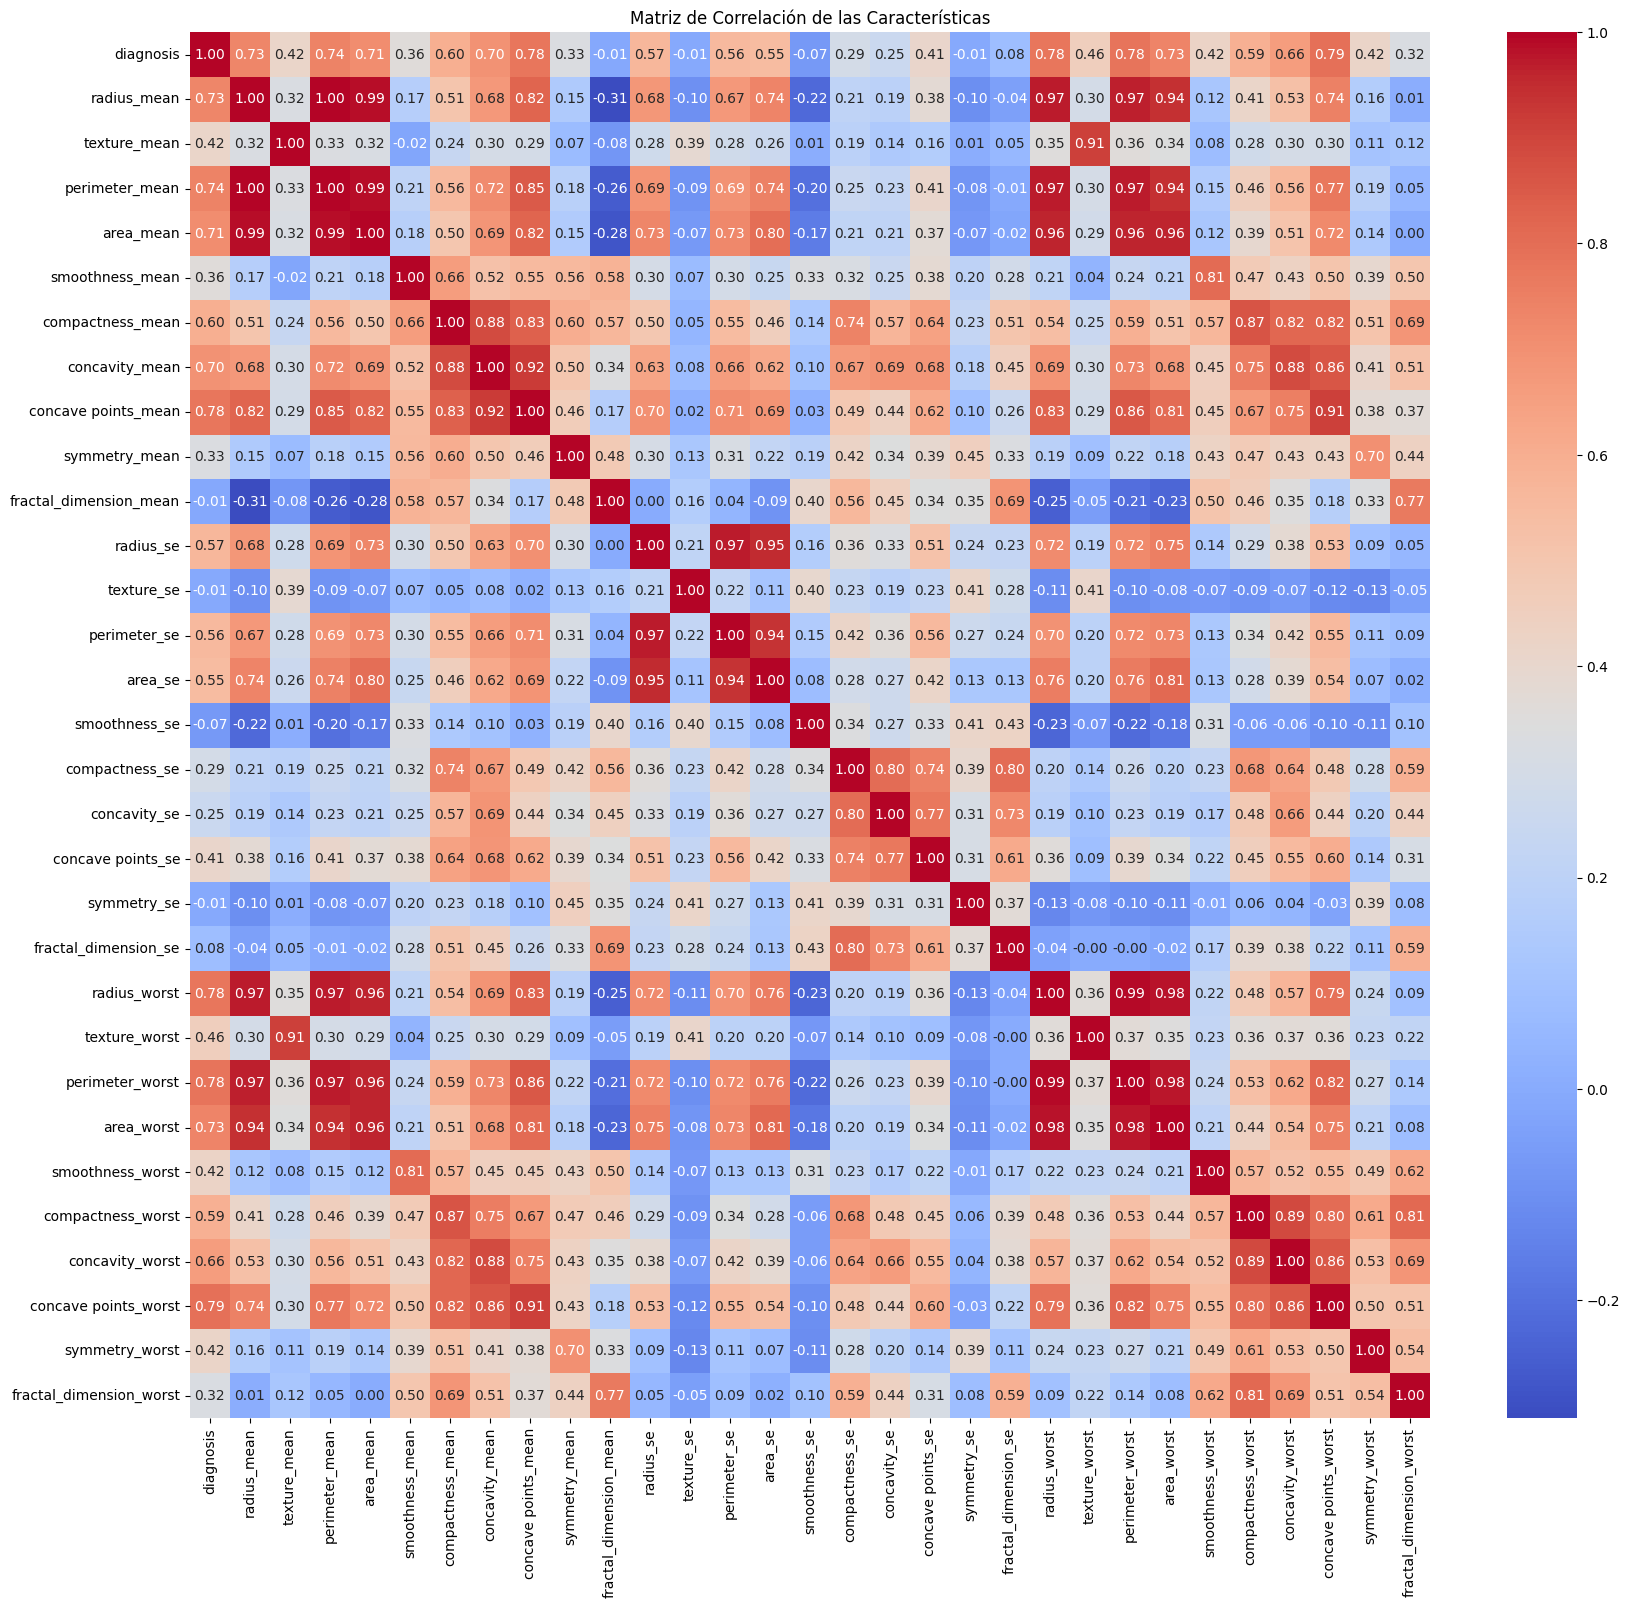

In [13]:
#matriz de correlacion

# Crear una copia del DataFrame para no modificar el original directamente
df_corr = df_nuevo.copy()

# Codificar la columna 'diagnosis' a valores numéricos
# 'M' y 'B' se convertirán a 0 y 1 o viceversa, dependiendo del orden alfanumérico
le = LabelEncoder()   #en este caso B->0 ,  M->1
df_corr['diagnosis'] = le.fit_transform(df_corr['diagnosis'])

# Excluir la columna 'id' ya que no es una característica relevante para la correlación
df_corr = df_corr.drop(columns=['id'], errors='ignore')

# Calcular la matriz de correlación
cm = df_corr.corr()

plt.figure(figsize=(20, 18)) # Ajustar el tamaño de la figura para una mejor visualización
sns.heatmap(cm, annot=True, cmap='coolwarm', fmt=".2f") # Usar un mapa de calor para visualizar la correlación
plt.title('Matriz de Correlación de las Características')
plt.show()

In [14]:
# Identificar las características más correlacionadas con 'diagnosis'

# Obtener las correlaciones de todas las características con 'diagnosis'
correlation_with_diagnosis = cm['diagnosis'].sort_values(ascending=False)

# Excluir la correlación de 'diagnosis' consigo misma, que siempre será 1.0
correlation_with_diagnosis = correlation_with_diagnosis.drop('diagnosis')

# Mostrar las características más correlacionadas (tanto positiva como negativamente)
print("Características más correlacionadas con 'diagnosis' (ordenadas por valor absoluto):\n")
display(correlation_with_diagnosis.abs().sort_values(ascending=False))

Características más correlacionadas con 'diagnosis' (ordenadas por valor absoluto):



,diagnosis
concave points_worst,0.793566
perimeter_worst,0.782914
concave points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


In [15]:
# Mostrar las características más correlacionadas con 'diagnosis' (sin valor absoluto)
# Una correlación negativa indica una asociación con diagnósticos benignos (0).
print("Características correlacionadas con 'diagnosis' (ordenadas de mayor a menor):\n")
display(correlation_with_diagnosis)

Características correlacionadas con 'diagnosis' (ordenadas de mayor a menor):



,diagnosis
concave points_worst,0.793566
perimeter_worst,0.782914
concave points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


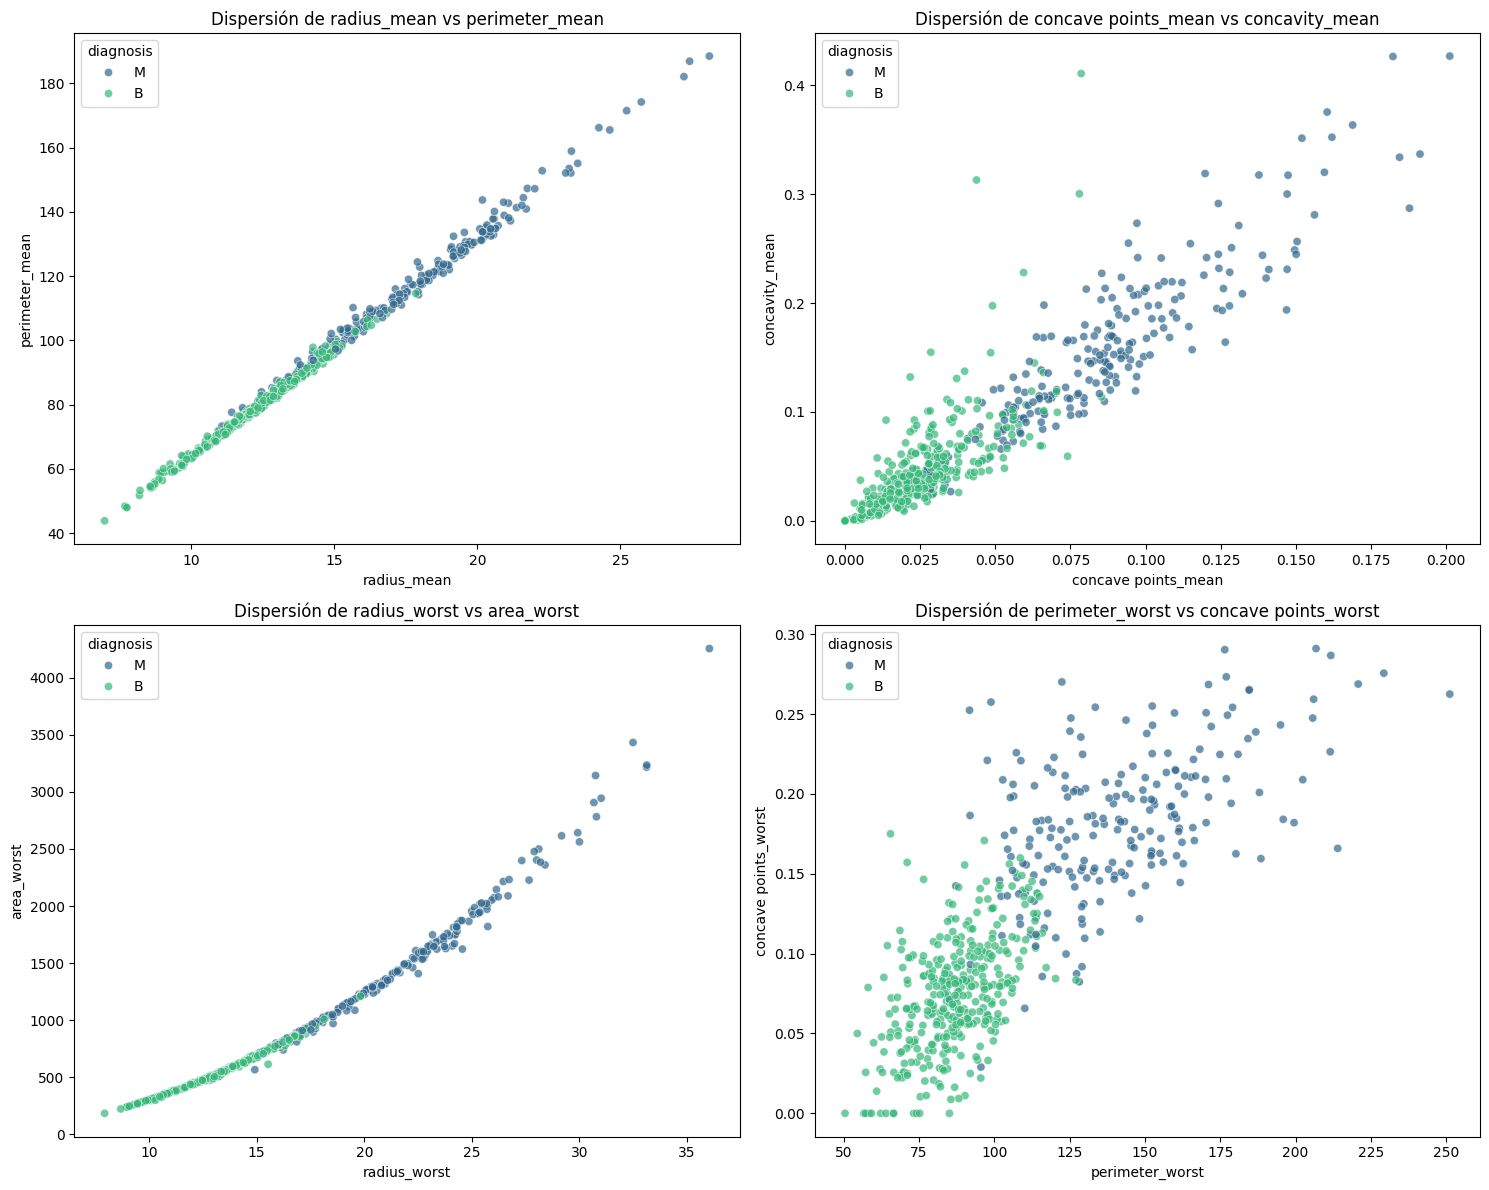

In [16]:
# Gráficos de dispersión para pares de variables relevantes

# Seleccionamos algunas de las características más correlacionadas con el diagnóstico
# y entre sí para visualizar sus relaciones.

relevant_features = [
    'radius_mean', 'perimeter_mean', 'area_mean',
    'concave points_mean', 'concavity_mean',
    'radius_worst', 'perimeter_worst', 'area_worst',
    'concave points_worst', 'concavity_worst'
]

# Creamos algunas combinaciones de pares para los scatter plots
pairs_to_plot = [
    ('radius_mean', 'perimeter_mean'),
    ('concave points_mean', 'concavity_mean'),
    ('radius_worst', 'area_worst'),
    ('perimeter_worst', 'concave points_worst')
]

plt.figure(figsize=(15, 12))
for i, (col1, col2) in enumerate(pairs_to_plot):
    plt.subplot(2, 2, i + 1) # 2 filas, 2 columnas de subgráficos
    sns.scatterplot(x=col1, y=col2, hue='diagnosis', data=df_nuevo, palette='viridis', alpha=0.7)
    plt.title(f'Dispersión de {col1} vs {col2}')
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.tight_layout()
plt.show()

## Análisis Multivariado

### Preparación de Datos para PCA

In [17]:
# Separar características (X) y la variable objetivo (y)
# Usaremos df_corr porque ya tiene 'id' eliminado y 'diagnosis' codificado numéricamente.
X = df_corr.drop('diagnosis', axis=1)
y = df_corr['diagnosis']

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

Dimensiones de X: (569, 30)
Dimensiones de y: (569,)


### Estandarización de las Características

PCA es sensible a la escala de las características, por lo que es crucial estandarizar los datos antes de aplicarlo.

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Primeras 5 filas de las características estandarizadas:")
print(pd.DataFrame(X_scaled, columns=X.columns).head())

Primeras 5 filas de las características estandarizadas:
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0     1.097064     -2.073335        1.269934   0.984375         1.568466   
1     1.829821     -0.353632        1.685955   1.908708        -0.826962   
2     1.579888      0.456187        1.566503   1.558884         0.942210   
3    -0.768909      0.253732       -0.592687  -0.764464         3.283553   
4     1.750297     -1.151816        1.776573   1.826229         0.280372   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0          3.283515        2.652874             2.532475       2.217515   
1         -0.487072       -0.023846             0.548144       0.001392   
2          1.052926        1.363478             2.037231       0.939685   
3          3.402909        1.915897             1.451707       2.867383   
4          0.539340        1.371011             1.428493      -0.009560   

   fractal_dimension_mean  ...  radi

### Aplicación de PCA

Ahora aplicaremos PCA a los datos estandarizados.

In [19]:
from sklearn.decomposition import PCA

# Puedes elegir el número de componentes o dejarlo como None para obtener todos los componentes
pca = PCA(n_components=None) # n_components=None para ver la varianza explicada por cada componente
X_pca = pca.fit_transform(X_scaled)

# Varianza explicada por cada componente principal
explained_variance_ratio = pca.explained_variance_ratio_
print("Varianza explicada por cada componente principal:\n", explained_variance_ratio)

# Suma acumulada de la varianza explicada
cumulative_explained_variance = np.cumsum(explained_variance_ratio)
print("Varianza explicada acumulada:\n", cumulative_explained_variance)

Varianza explicada por cada componente principal:
 [4.42720256e-01 1.89711820e-01 9.39316326e-02 6.60213492e-02
 5.49576849e-02 4.02452204e-02 2.25073371e-02 1.58872380e-02
 1.38964937e-02 1.16897819e-02 9.79718988e-03 8.70537901e-03
 8.04524987e-03 5.23365745e-03 3.13783217e-03 2.66209337e-03
 1.97996793e-03 1.75395945e-03 1.64925306e-03 1.03864675e-03
 9.99096464e-04 9.14646751e-04 8.11361259e-04 6.01833567e-04
 5.16042379e-04 2.72587995e-04 2.30015463e-04 5.29779290e-05
 2.49601032e-05 4.43482743e-06]
Varianza explicada acumulada:
 [0.44272026 0.63243208 0.72636371 0.79238506 0.84734274 0.88758796
 0.9100953  0.92598254 0.93987903 0.95156881 0.961366   0.97007138
 0.97811663 0.98335029 0.98648812 0.98915022 0.99113018 0.99288414
 0.9945334  0.99557204 0.99657114 0.99748579 0.99829715 0.99889898
 0.99941502 0.99968761 0.99991763 0.99997061 0.99999557 1.        ]


### Visualización de la Varianza Explicada

Visualizaremos cuánta varianza explica cada componente principal y la varianza acumulada para decidir cuántos componentes conservar.

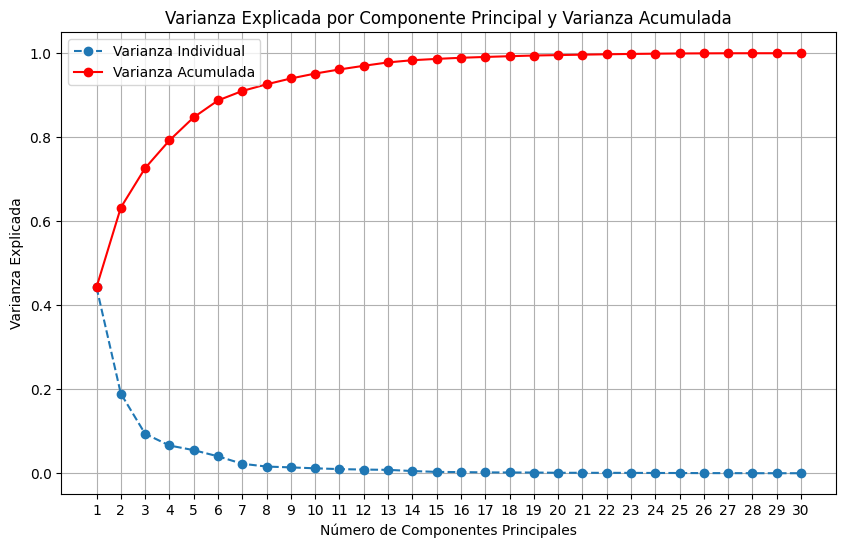

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o', linestyle='--')
plt.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='-', color='red')
plt.title('Varianza Explicada por Componente Principal y Varianza Acumulada')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada')
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, 1))
plt.grid(True)
plt.legend(['Varianza Individual', 'Varianza Acumulada'])
plt.show()

### Visualización de los dos primeros Componentes Principales

Para una visualización de los datos en 2D, podemos graficar las dos primeras componentes principales, que suelen capturar la mayor parte de la varianza.

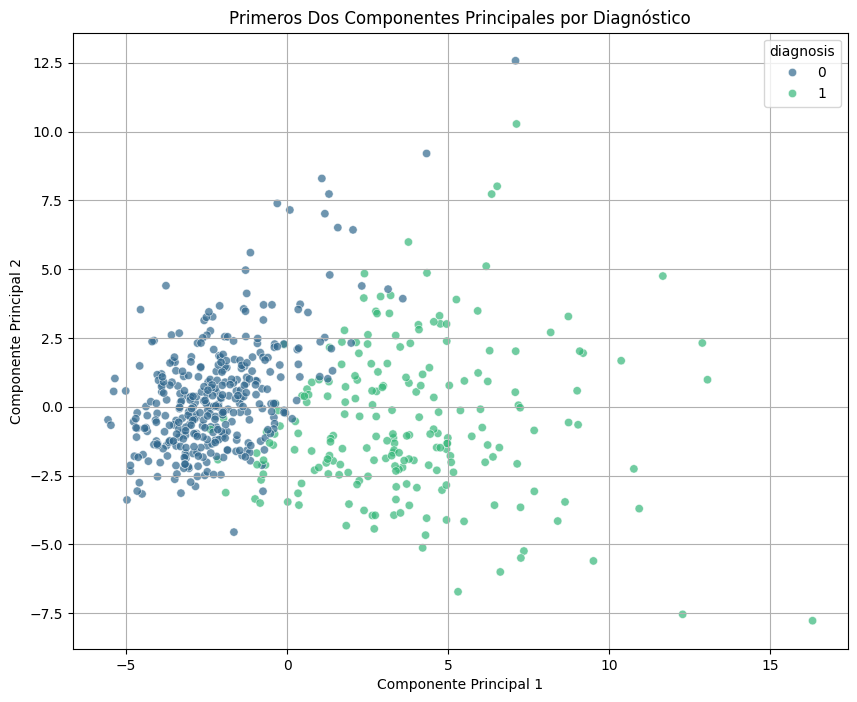

In [21]:
# Para visualizar, usaremos solo los dos primeros componentes principales
pca_2_components = PCA(n_components=2)
X_pca_2d = pca_2_components.fit_transform(X_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_pca_2d[:, 0], y=X_pca_2d[:, 1],
    hue=y, # Usamos la variable objetivo para colorear los puntos
    palette='viridis', # O 'coolwarm', 'RdBu', etc.
    alpha=0.7
)
plt.title('Primeros Dos Componentes Principales por Diagnóstico')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

# Construcción de Modelos de Clasificación

## Modelo 1: Regresión Logística

### División de Datos en Conjuntos de Entrenamiento y Prueba

Dividiremos nuestros datos estandarizados (`X_scaled`) y la variable objetivo (`y`) en conjuntos de entrenamiento y prueba para evaluar el rendimiento del modelo en datos no vistos.

In [40]:
from sklearn.model_selection import train_test_split

# Dividir los datos (X_scaled es el resultado de PCA si se usó, o el X estandarizado original)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=111, stratify=y)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de y_test: {y_test.shape}")

Dimensiones de X_train: (398, 30)
Dimensiones de X_test: (171, 30)
Dimensiones de y_train: (398,)
Dimensiones de y_test: (171,)


### Entrenamiento del Modelo de Regresión Logística

Ahora entrenaremos el modelo utilizando el conjunto de entrenamiento.

In [23]:
from sklearn.linear_model import LogisticRegression

# Inicializar y entrenar el modelo de Regresión Logística
log_reg_model = LogisticRegression(random_state=42, solver='liblinear') # 'liblinear' es bueno para datasets pequeños y L1/L2 regularization
log_reg_model.fit(X_train, y_train)

print("Modelo de Regresión Logística entrenado exitosamente.")

Modelo de Regresión Logística entrenado exitosamente.


### Predicciones y Evaluación del Modelo

Una vez entrenado el modelo, realizaremos predicciones sobre el conjunto de prueba y evaluaremos su rendimiento utilizando métricas clave.


Accuracy: 0.9766081871345029

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98       107
           1       0.97      0.97      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171


Confusion Matrix:
 [[105   2]
 [  2  62]]


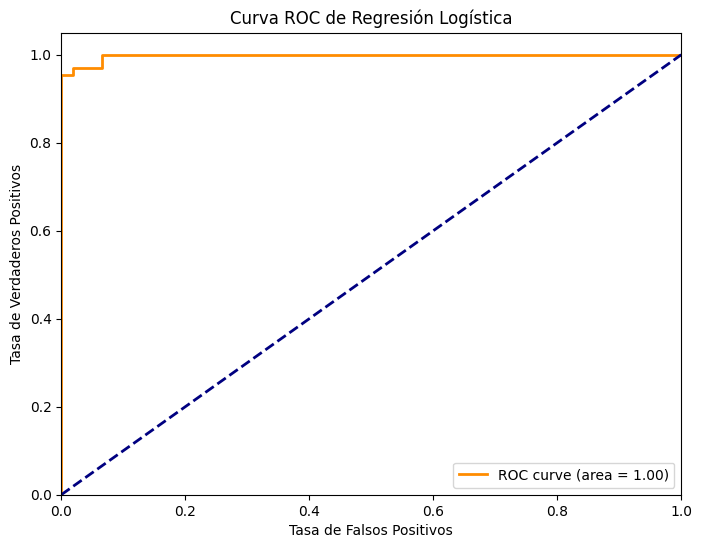

In [24]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

# Hacer predicciones en el conjunto de prueba
y_pred = log_reg_model.predict(X_test)
y_pred_proba = log_reg_model.predict_proba(X_test)[:, 1]

# Evaluar el modelo
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Curva ROC y AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC de Regresión Logística')
plt.legend(loc='lower right')
plt.show()

##Modelo 2: Máquinas de Soporte Vectorial (SVM)

###Kernel Polinomial

#### Entrenamiento del Modelo SVM con Kernel Polinomial

Entrenaremos un modelo SVM utilizando un **kernel polinomial**. Este kernel puede capturar relaciones no lineales complejas al mapear los datos a un espacio de características de mayor dimensión.

In [25]:
from sklearn.svm import SVC

# Inicializar y entrenar el modelo SVM con un kernel polinomial
# Puedes ajustar 'degree' para cambiar el grado del polinomio (ej. degree=2 o degree=3)
svm_poly_model = SVC(kernel='poly', degree=3, random_state=42, probability=True) # probability=True para obtener probabilidades y calcular ROC-AUC
svm_poly_model.fit(X_train, y_train)

print("Modelo SVM con kernel polinomial entrenado exitosamente.")

Modelo SVM con kernel polinomial entrenado exitosamente.


#### Predicciones y Evaluación del Modelo SVM con Kernel Polinomial

Realizaremos predicciones sobre el conjunto de prueba y evaluaremos el rendimiento del modelo SVM con kernel polinomial.


Accuracy (SVM Polinomial): 0.9122807017543859

Classification Report (SVM Polinomial):
               precision    recall  f1-score   support

           0       0.88      1.00      0.93       107
           1       1.00      0.77      0.87        64

    accuracy                           0.91       171
   macro avg       0.94      0.88      0.90       171
weighted avg       0.92      0.91      0.91       171


Confusion Matrix (SVM Polinomial):
 [[107   0]
 [ 15  49]]


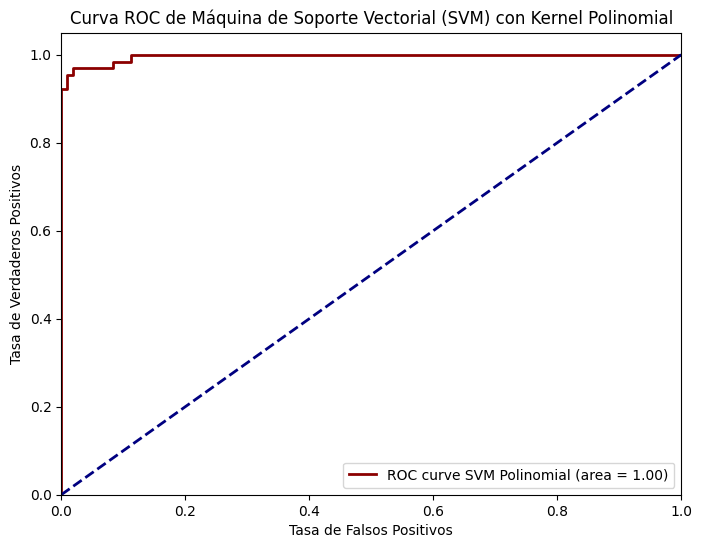

In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

# Hacer predicciones en el conjunto de prueba
y_pred_svm_poly = svm_poly_model.predict(X_test)
y_pred_proba_svm_poly = svm_poly_model.predict_proba(X_test)[:, 1]

# Evaluar el modelo
print("\nAccuracy (SVM Polinomial):", accuracy_score(y_test, y_pred_svm_poly))

print("\nClassification Report (SVM Polinomial):\n", classification_report(y_test, y_pred_svm_poly))

print("\nConfusion Matrix (SVM Polinomial):\n", confusion_matrix(y_test, y_pred_svm_poly))

# Curva ROC y AUC para SVM Polinomial
fpr_svm_poly, tpr_svm_poly, thresholds_svm_poly = roc_curve(y_test, y_pred_proba_svm_poly)
roc_auc_svm_poly = auc(fpr_svm_poly, tpr_svm_poly)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm_poly, tpr_svm_poly, color='darkred', lw=2, label=f'ROC curve SVM Polinomial (area = {roc_auc_svm_poly:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC de Máquina de Soporte Vectorial (SVM) con Kernel Polinomial')
plt.legend(loc='lower right')
plt.show()

### Kernel Radial

#### Entrenamiento del Modelo SVM con Kernel RBF

Ahora, entrenaremos un modelo SVM utilizando un kernel de **Función de Base Radial (RBF)**, que es un kernel no lineal muy popular y efectivo para capturar relaciones complejas en los datos.

In [27]:
from sklearn.svm import SVC

# Inicializar y entrenar el modelo SVM con un kernel RBF
svm_rbf_model = SVC(kernel='rbf', random_state=42, probability=True) # probability=True para obtener probabilidades y calcular ROC-AUC
svm_rbf_model.fit(X_train, y_train)

print("Modelo SVM con kernel RBF entrenado exitosamente.")

Modelo SVM con kernel RBF entrenado exitosamente.


#### Predicciones y Evaluación del Modelo SVM con Kernel RBF

Realizaremos predicciones sobre el conjunto de prueba y evaluaremos el rendimiento del modelo SVM con kernel RBF.


Accuracy (SVM RBF): 0.9707602339181286

Classification Report (SVM RBF):
               precision    recall  f1-score   support

           0       0.97      0.98      0.98       107
           1       0.97      0.95      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171


Confusion Matrix (SVM RBF):
 [[105   2]
 [  3  61]]


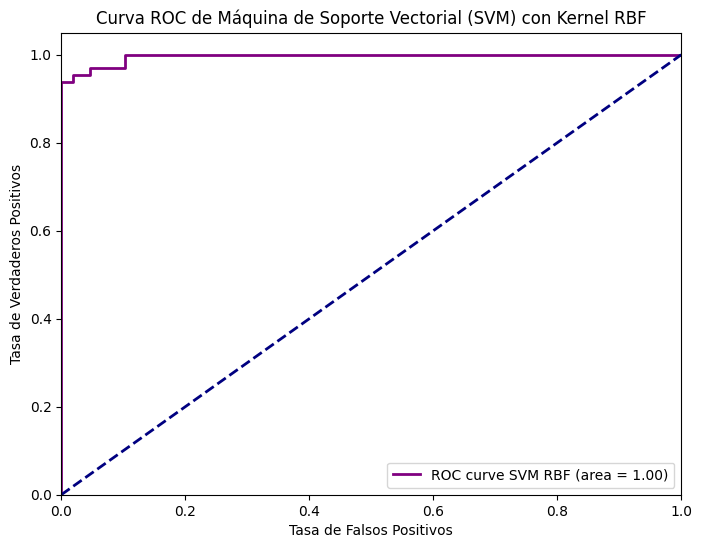

In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

# Hacer predicciones en el conjunto de prueba
y_pred_svm_rbf = svm_rbf_model.predict(X_test)
y_pred_proba_svm_rbf = svm_rbf_model.predict_proba(X_test)[:, 1]

# Evaluar el modelo
print("\nAccuracy (SVM RBF):", accuracy_score(y_test, y_pred_svm_rbf))

print("\nClassification Report (SVM RBF):\n", classification_report(y_test, y_pred_svm_rbf))

print("\nConfusion Matrix (SVM RBF):\n", confusion_matrix(y_test, y_pred_svm_rbf))

# Curva ROC y AUC para SVM RBF
fpr_svm_rbf, tpr_svm_rbf, thresholds_svm_rbf = roc_curve(y_test, y_pred_proba_svm_rbf)
roc_auc_svm_rbf = auc(fpr_svm_rbf, tpr_svm_rbf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm_rbf, tpr_svm_rbf, color='purple', lw=2, label=f'ROC curve SVM RBF (area = {roc_auc_svm_rbf:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC de Máquina de Soporte Vectorial (SVM) con Kernel RBF')
plt.legend(loc='lower right')
plt.show()

### Kernel Lineal

#### Entrenamiento del Modelo SVM

Entrenaremos el modelo SVM utilizando el conjunto de entrenamiento. Para este primer intento, usaremos un kernel lineal, que suele ser un buen punto de partida.

In [41]:
from sklearn.svm import SVC

# Inicializar y entrenar el modelo SVM con un kernel lineal
svm_model = SVC(kernel='linear', random_state=42, probability=True) # probability=True para obtener probabilidades y calcular ROC-AUC
svm_model.fit(X_train, y_train)

print("Modelo SVM entrenado exitosamente.")

Modelo SVM entrenado exitosamente.


#### Predicciones y Evaluación del Modelo SVM

Realizaremos predicciones sobre el conjunto de prueba y evaluaremos el rendimiento del modelo SVM.


Accuracy (SVM): 0.9707602339181286

Classification Report (SVM):
               precision    recall  f1-score   support

           0       0.97      0.98      0.98       107
           1       0.97      0.95      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171


Confusion Matrix (SVM):
 [[105   2]
 [  3  61]]


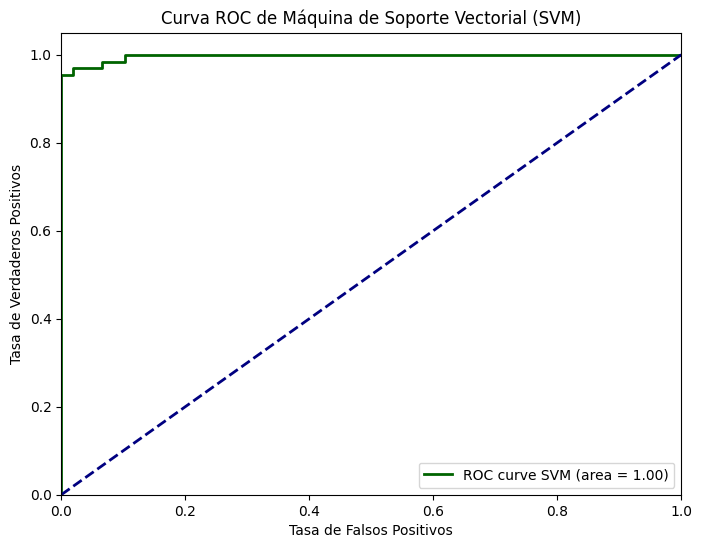

In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

# Hacer predicciones en el conjunto de prueba
y_pred_svm = svm_model.predict(X_test)
y_pred_proba_svm = svm_model.predict_proba(X_test)[:, 1]

# Evaluar el modelo
print("\nAccuracy (SVM):", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report (SVM):\n", classification_report(y_test, y_pred_svm))

print("\nConfusion Matrix (SVM):\n", confusion_matrix(y_test, y_pred_svm))

# Curva ROC y AUC para SVM
fpr_svm, tpr_svm, thresholds_svm = roc_curve(y_test, y_pred_proba_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm, tpr_svm, color='darkgreen', lw=2, label=f'ROC curve SVM (area = {roc_auc_svm:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC de Máquina de Soporte Vectorial (SVM)')
plt.legend(loc='lower right')
plt.show()


## Optimización de Hiperparámetros con GridSearch para SVM Lineal

Para mejorar el rendimiento del modelo SVM con kernel lineal, aplicaremos la técnica de optimización de hiperparámetros conocida como **GridSearch (Búsqueda en Rejilla)**. Esta estrategia explora sistemáticamente todas las combinaciones posibles de un conjunto predefinido de valores de hiperparámetros para identificar la combinación óptima.

En el caso del SVM lineal, el hiperparámetro más crítico a optimizar es **`C` (parámetro de regularización)**.

*   **`C` (Coste/Penalización)**: Controla la penalización por errores de clasificación en el entrenamiento. Un `C` pequeño crea un margen más amplio, tolerando más errores de clasificación (mayor regularización), lo que puede llevar a un modelo más generalizable pero potencialmente con mayor sesgo. Un `C` grande penaliza fuertemente los errores, resultando en un margen más estrecho que busca clasificar correctamente todos los puntos de entrenamiento (menor regularización), lo que puede llevar a sobreajuste.

La optimización de `C` es crucial porque un valor inadecuado puede resultar en un modelo que no generaliza bien a datos nuevos, ya sea por sobreajuste (demasiado complejo, bajo `C`) o por subajuste (demasiado simple, alto `C`). GridSearch nos permitirá encontrar el equilibrio adecuado para nuestro conjunto de datos.

### Preparar para GridSearch con SVM lineal



In [43]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV ha sido importado con éxito.")

GridSearchCV ha sido importado con éxito.


### Definir Parámetros para GridSearch (SVM Lineal)


Seleccionar el modelo SVM con kernel 'linear' y definir un espacio de búsqueda (grid) de hiperparámetros a explorar, centrándonos principalmente en el parámetro 'C'.


In [44]:
from sklearn.svm import SVC

# Crear una instancia del modelo SVM con kernel lineal
svm_linear_model = SVC(kernel='linear', random_state=42, probability=True)

# Definir el espacio de búsqueda para el hiperparámetro 'C'
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

print("Modelo SVM lineal y espacio de búsqueda de hiperparámetros definidos.")

Modelo SVM lineal y espacio de búsqueda de hiperparámetros definidos.


In [50]:
from sklearn.model_selection import GridSearchCV

# Inicializar GridSearchCV
# cv=5 indica validación cruzada de 5 pliegues (k-fold cross-validation)
# scoring='accuracy' indica que la métrica de evaluación para seleccionar el mejor modelo será la precisión
# n_jobs=-1 utiliza todos los procesadores disponibles para acelerar el cálculo
grid_search_svm_linear = GridSearchCV(estimator=svm_linear_model, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# Ejecutar GridSearch en los datos de entrenamiento
grid_search_svm_linear.fit(X_train, y_train)

print("GridSearch con SVM lineal completado.")

Fitting 5 folds for each of 7 candidates, totalling 35 fits
GridSearch con SVM lineal completado.


In [51]:
print("Mejores hiperparámetros encontrados:", grid_search_svm_linear.best_params_)
print("Mejor score de validación cruzada (Accuracy):", grid_search_svm_linear.best_score_)


Mejores hiperparámetros encontrados: {'C': 0.1}
Mejor score de validación cruzada (Accuracy): 0.9774050632911392



Accuracy (SVM Lineal Optimizado): 0.9766081871345029

Classification Report (SVM Lineal Optimizado):
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       107
           1       0.98      0.95      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171


Confusion Matrix (SVM Lineal Optimizado):
 [[106   1]
 [  3  61]]


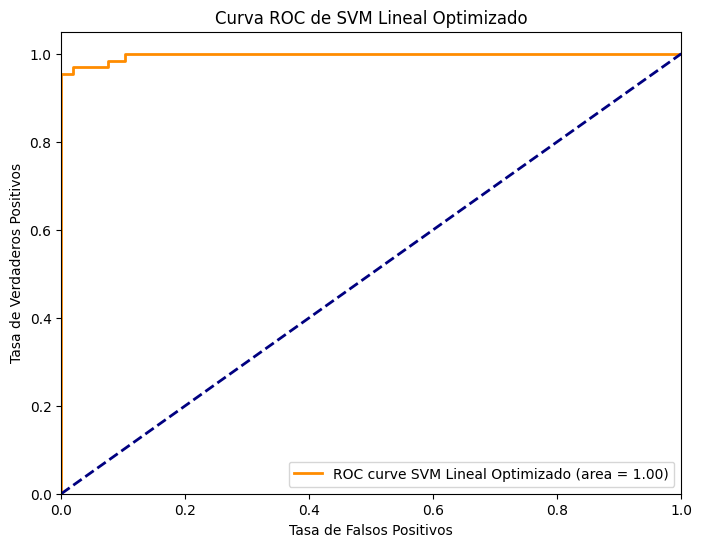

In [52]:
best_svm_linear_model = grid_search_svm_linear.best_estimator_

# Hacer predicciones en el conjunto de prueba con el mejor modelo
y_pred_best_svm = best_svm_linear_model.predict(X_test)
y_pred_proba_best_svm = best_svm_linear_model.predict_proba(X_test)[:, 1]

# Evaluar el modelo
print("\nAccuracy (SVM Lineal Optimizado):", accuracy_score(y_test, y_pred_best_svm))

print("\nClassification Report (SVM Lineal Optimizado):\n", classification_report(y_test, y_pred_best_svm))

print("\nConfusion Matrix (SVM Lineal Optimizado):\n", confusion_matrix(y_test, y_pred_best_svm))

# Curva ROC y AUC para SVM Lineal Optimizado
fpr_best_svm, tpr_best_svm, thresholds_best_svm = roc_curve(y_test, y_pred_proba_best_svm)
roc_auc_best_svm = auc(fpr_best_svm, tpr_best_svm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_best_svm, tpr_best_svm, color='darkorange', lw=2, label=f'ROC curve SVM Lineal Optimizado (area = {roc_auc_best_svm:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC de SVM Lineal Optimizado')
plt.legend(loc='lower right')
plt.show()